## Question 1 ##

In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [2]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

In [3]:
# Parameters
sigma_min = 4
sigma_max = 40
n_scales = 20
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)

scale_space = np.zeros((gray.shape[0], gray.shape[1], n_scales), dtype=np.float32)

for i, s in enumerate(sigmas):
    blurred = cv.GaussianBlur(gray, (0, 0), s)
    lap = cv.Laplacian(blurred, cv.CV_32F)
    scale_space[:, :, i] = (s**2 * lap) ** 2   # Normalized, squared so bright and dark blobs both give peaks

print(scale_space.shape)
print(sigmas.round(2))

(360, 360, 20)
[ 4.    4.52  5.1   5.75  6.5   7.33  8.28  9.34 10.55 11.91 13.44 15.17
 17.13 19.33 21.82 24.63 27.81 31.39 35.43 40.  ]


0.14518465
16 blobs found
16 blobs after suppression
15 blobs after removing border ones
7 blobs at sigma_min


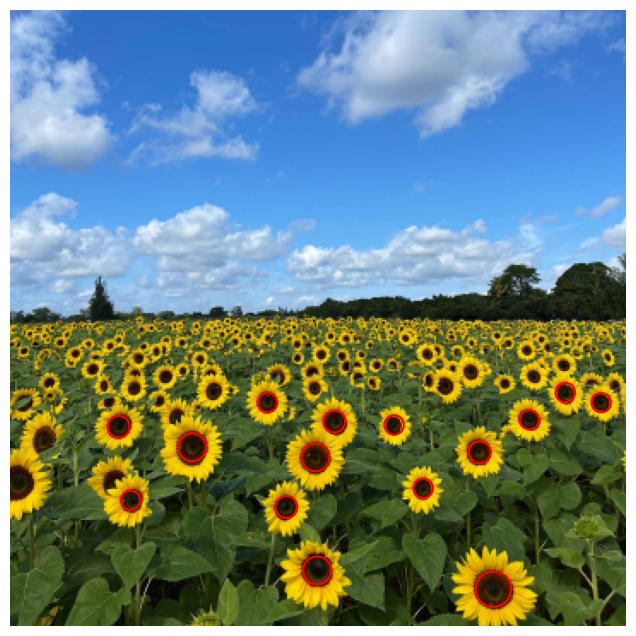

Sigma range used: 4 to 40 (20 scales, geometric)
Largest circles (x, y, radius, sigma):
  x=282, y=338, r=10.4, sigma=7.3
  x=178, y=261, r=8.1, sigma=5.8
  x=179, y=327, r=8.1, sigma=5.8
  x=106, y=255, r=8.1, sigma=5.8
  x=63, y=243, r=6.4, sigma=4.5


In [4]:
from scipy.ndimage import maximum_filter

print(scale_space.max())

# Detect extrema
threshold = 0.63 * scale_space.max()   # Tune: 0.3, 0.4, 0.5
local_max = maximum_filter(scale_space, size=(3, 3, 3)) == scale_space
mask = local_max & (scale_space > threshold)

ys, xs, si = np.where(mask)
radii = np.sqrt(2) * sigmas[si]
print(len(xs), 'blobs found')

# Suppression
responses = scale_space[ys, xs, si]
order = np.argsort(-responses)
keep = []
for i in order:
    ok = True
    for j in keep:
        d = np.hypot(xs[i] - xs[j], ys[i] - ys[j])
        if d < max(radii[i], radii[j]):
            ok = False
            break
    if ok:
        keep.append(i)

keep = np.array(keep)
bx, by, br, bs = xs[keep], ys[keep], radii[keep], sigmas[si[keep]]
print(len(bx), 'blobs after suppression')

# Remove blobs whose circle crosses the border
h, w = gray.shape
inside = (bx - br >= 0) & (bx + br < w) & (by - br >= 0) & (by + br < h)
bx, by, br, bs = bx[inside], by[inside], br[inside], bs[inside]
print(len(bx), 'blobs after removing border ones')
print((bs <= sigmas[0] + 1e-6).sum(), 'blobs at sigma_min')

# Drawing the blobs
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
for x, y, r in zip(bx, by, br):
    ax.add_patch(plt.Circle((x, y), r, color='red', fill=False, linewidth=1.5))
ax.axis('off')
plt.show()

# Report the values
top = np.argsort(-br)[:5]
print('Sigma range used:', sigma_min, 'to', sigma_max, f'({n_scales} scales, geometric)')
print('Largest circles (x, y, radius, sigma):')
for k in top:
    print(f'  x={bx[k]}, y={by[k]}, r={br[k]:.1f}, sigma={bs[k]:.1f}')

*Explanation*

The sunflower image was loaded at quarter resolution (360 × 360), converted to grayscale and normalized to [0, 1]. For each σ, the image was blurred with a Gaussian and the Laplacian was applied, then multiplied by σ² to get the scale-normalized LoG, σ²∇²G. The responses were squared so that bright and dark blobs both give positive peaks. A pixel was accepted as a blob if it was a local maximum in a 3 × 3 × 3 neighbourhood (y, x, σ) and above a threshold. Overlapping detections were suppressed by keeping the strongest one, and blobs whose circles crossed the image boundary were removed. Each blob is drawn as a circle of radius r = √2 σ.

**Parameters**
- **Scale range:** σ = 4 to 40, using 20 geometrically spaced values.
- **Threshold:** 0.63 × maximum response (≈ 0.094).
- **Neighbourhood:** 3 × 3 × 3.
- **Circle radius:** r = √2 σ.

**Results** \
The detector found 16 candidates, 16 after overlap suppression and 15 after removing boundary blobs. The largest circles are listed below (coordinates in the quarter-size image).

| x (px) | y (px) | Radius (px) | σ |
|---:|---:|---:|---:|
| 282 | 338 | 10.4 | 7.3 |
| 178 | 261 | 8.1 | 5.8 |
| 179 | 327 | 8.1 | 5.8 |

**Discussion** \
At this threshold, the detections lie on sunflower heads. The largest detected scale (σ = 7.3) was well below σ_max = 40, so the upper limit was not restrictive. 7 of the 15 detections sit at σ_min = 4, so some small flowers may be clipped by the lower end of the range. A threshold of 0.2 gave 111 blobs, many on leaf texture and image borders. At 0.4, detections still appeared on tree clumps behind the field (including the two largest circles, r = 19.0 and 16.8), so I raised it to 0.63. This removes the tree detections but also misses fainter or more distant flowers, so there is a trade-off between false detections and missed flowers.

## Question 2 ##

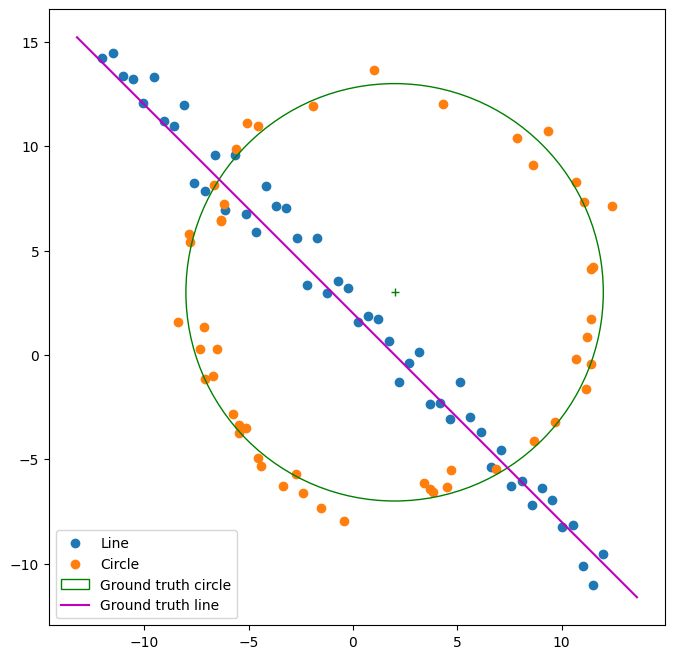

In [5]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

np.random.seed(0)

N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3

# noisy circle
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

# noisy line
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='g')
x_ = np.array(ax.get_xlim())
ax.plot(x_, m*x_ + b, color='m', label='Ground truth line')
ax.set_aspect('equal')
ax.legend()
plt.show()

**(a) RANSAC line**

In [6]:
def line_from_two_points(p1, p2):
    dx, dy = p2 - p1
    nrm = np.hypot(dx, dy)
    a, b = -dy / nrm, dx / nrm   # Unit normal
    d = a * p1[0] + b * p1[1]
    return a, b, d

def fit_line_tls(P):
    c = P.mean(axis=0)
    _, _, Vt = np.linalg.svd(P - c)
    a, b = Vt[-1]   # Unit normal by construction
    d = a * c[0] + b * c[1]
    return a, b, d

def line_error(P, a, b, d):
    return np.abs(a * P[:, 0] + b * P[:, 1] - d)   # Normal distance

rng = np.random.default_rng(0)

line_thresh = 1.0
line_min_inliers = 40
n_iter = 200

best_count = 0
best_line_inliers = None
best_line_sample = None
best_line_sample_model = None

for _ in range(n_iter):
    idx = rng.choice(len(X), 2, replace=False)
    a, b_, d = line_from_two_points(X[idx[0]], X[idx[1]])
    inl = line_error(X, a, b_, d) < line_thresh
    if inl.sum() > best_count:
        best_count = inl.sum()
        best_line_inliers = inl
        best_line_sample = X[idx]
        best_line_sample_model = (a, b_, d)

assert best_count >= line_min_inliers
a_l, b_l, d_l = fit_line_tls(X[best_line_inliers])

print('best consensus:', best_count, '(min required:', line_min_inliers, ')')
print('RANSAC line: a=%.3f b=%.3f d=%.3f, norm=%.3f' % (a_l, b_l, d_l, np.hypot(a_l, b_l)))
print('ground truth: a=%.3f b=%.3f d=%.3f' % (1/np.sqrt(2), 1/np.sqrt(2), 2/np.sqrt(2)))

best consensus: 44 (min required: 40 )
RANSAC line: a=0.725 b=0.689 d=1.782, norm=1.000
ground truth: a=0.707 b=0.707 d=1.414


**Explanation**

The best consensus contained 44 inliers, exceeding the minimum of 40. The fitted line parameters were \((a,b,d)=(0.725, 0.689, 1.782)\), close to the ground truth \((0.707, 0.707, 1.414)\). The small difference is due to noise and a few circle points near the intersections being included as inliers.

**(b) RANSAC circle on the remnant**

In [7]:
def circle_from_three_points(p1, p2, p3):
    A = np.array([[p1[0], p1[1], 1],
                  [p2[0], p2[1], 1],
                  [p3[0], p3[1], 1]])
    rhs = -np.array([p1 @ p1, p2 @ p2, p3 @ p3])
    try:
        D, E, F = np.linalg.solve(A, rhs)
    except np.linalg.LinAlgError:
        return None
    cx, cy = -D / 2, -E / 2
    return cx, cy, np.sqrt(cx**2 + cy**2 - F)

def circle_error(P, cx, cy, rad):
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rad)   # Radial error

def fit_circle_opt(P, init):
    cost = lambda p: np.sum(circle_error(P, p[0], p[1], p[2])**2)
    return minimize(cost, init).x

X_rem = X[~best_line_inliers]

circ_thresh = 1.0
circ_min_inliers = 35
n_iter_c = 500

best_count_c = 0
best_circ_inliers = None
best_circ_sample = None
best_circ_sample_model = None

for _ in range(n_iter_c):
    idx = rng.choice(len(X_rem), 3, replace=False)
    model = circle_from_three_points(*X_rem[idx])
    if model is None:
        continue
    inl = circle_error(X_rem, *model) < circ_thresh
    if inl.sum() > best_count_c:
        best_count_c = inl.sum()
        best_circ_inliers = inl
        best_circ_sample = X_rem[idx]
        best_circ_sample_model = model

assert best_count_c >= circ_min_inliers
cx, cy, rc = fit_circle_opt(X_rem[best_circ_inliers], best_circ_sample_model)

print('remaining points:', len(X_rem))
print('best consensus:', best_count_c, '(min required:', circ_min_inliers, ')')
print('RANSAC circle: centre=(%.2f, %.2f), r=%.2f' % (cx, cy, rc))
print('ground truth : centre=(2, 3), r=10')

remaining points: 56
best consensus: 45 (min required: 35 )
RANSAC circle: centre=(1.82, 3.03), r=9.82
ground truth : centre=(2, 3), r=10


**Explanation**

The best consensus contained 45 inliers, exceeding the minimum required of 35. The fitted circle had centre = (1.82, 3.03) and radius = 9.82, close to the ground truth centre = (2, 3) and radius = 10. The small differences are due to noise and possible inclusion of a few outliers.

**(c) Combined Plots**

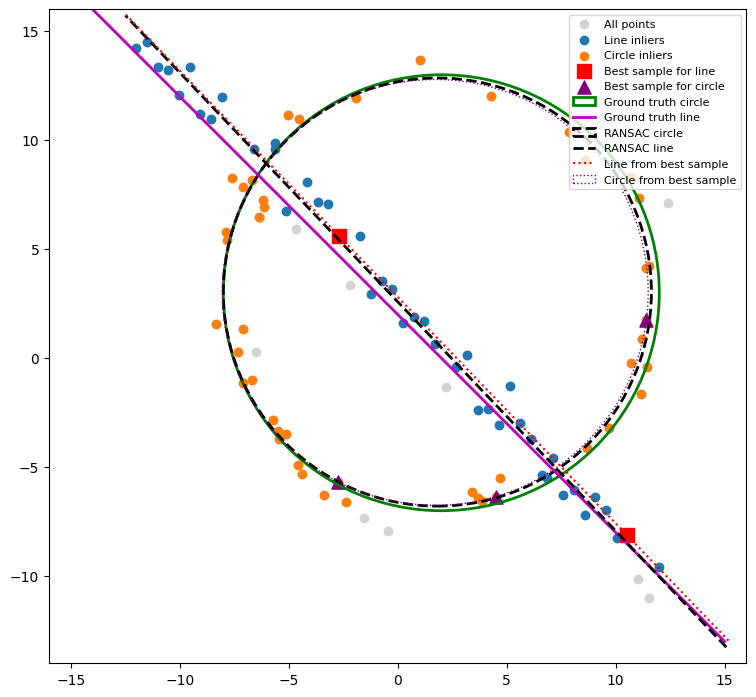

In [8]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(X[:, 0], X[:, 1], c='lightgray', label='All points')
ax.scatter(*X[best_line_inliers].T, c='tab:blue', label='Line inliers')
ax.scatter(*X_rem[best_circ_inliers].T, c='tab:orange', label='Circle inliers')

# Best samples
ax.scatter(*best_line_sample.T, c='red', marker='s', s=90, label='Best sample for line')
ax.scatter(*best_circ_sample.T, c='purple', marker='^', s=90, label='Best sample for circle')

# Ground truth
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, linewidth=2, label='Ground truth circle'))
xs_ = np.array([-15, 15])
ax.plot(xs_, m*xs_ + b, color='m', linewidth=2, label='Ground truth line')

# RANSAC results
ax.add_patch(plt.Circle((cx, cy), rc, color='k', fill=False, linestyle='--', linewidth=2, label='RANSAC circle'))
tt = np.linspace(-20, 20, 2)
p0 = d_l * np.array([a_l, b_l]); dirn = np.array([-b_l, a_l])
L = p0 + tt[:, None] * dirn
ax.plot(L[:, 0], L[:, 1], 'k--', linewidth=2, label='RANSAC line')

# Models from the best samples only
a_s, b_s, d_s = best_line_sample_model
p0s = d_s * np.array([a_s, b_s]); dirs = np.array([-b_s, a_s])
Ls = p0s + tt[:, None] * dirs
ax.plot(Ls[:, 0], Ls[:, 1], color='red', linestyle=':', label='Line from best sample')
ax.add_patch(plt.Circle(best_circ_sample_model[:2], best_circ_sample_model[2],
                        color='purple', fill=False, linestyle=':', label='Circle from best sample'))

ax.set_xlim(-16, 16); ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.legend(fontsize=8, loc='upper right')
plt.show()

**(d) What will happen if we fit the circle first?**

circle-first: consensus 52 | centre=(1.92, 3.20), r=9.84
line after circle: consensus 41 | a=-0.721 b=-0.693 d=-1.704


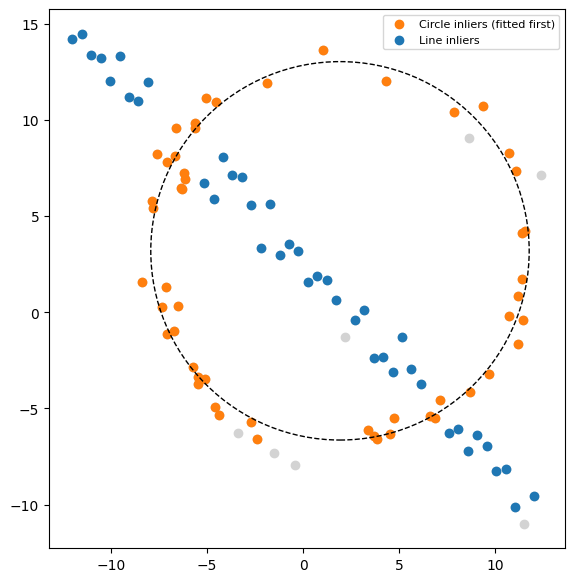

In [9]:
rng2 = np.random.default_rng(1)
best_c, best_inl_c, best_model_c = 0, None, None
for _ in range(500):
    idx = rng2.choice(len(X), 3, replace=False)
    model = circle_from_three_points(*X[idx])
    if model is None:
        continue
    inl = circle_error(X, *model) < circ_thresh
    if inl.sum() > best_c:
        best_c, best_inl_c, best_model_c = inl.sum(), inl, model

cx2, cy2, rc2 = fit_circle_opt(X[best_inl_c], best_model_c)
print('circle-first: consensus', best_c, '| centre=(%.2f, %.2f), r=%.2f' % (cx2, cy2, rc2))

X_rem2 = X[~best_inl_c]
best_l, best_inl_l = 0, None
for _ in range(200):
    idx = rng2.choice(len(X_rem2), 2, replace=False)
    a, b_, d = line_from_two_points(X_rem2[idx[0]], X_rem2[idx[1]])
    inl = line_error(X_rem2, a, b_, d) < line_thresh
    if inl.sum() > best_l:
        best_l, best_inl_l = inl.sum(), inl
a2, b2, d2 = fit_line_tls(X_rem2[best_inl_l])
print('line after circle: consensus', best_l, '| a=%.3f b=%.3f d=%.3f' % (a2, b2, d2))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], c='lightgray')
ax.scatter(*X[best_inl_c].T, c='tab:orange', label='Circle inliers (fitted first)')
ax.scatter(*X_rem2[best_inl_l].T, c='tab:blue', label='Line inliers')
ax.add_patch(plt.Circle((cx2, cy2), rc2, color='k', fill=False, linestyle='--'))
ax.set_aspect('equal'); ax.legend(fontsize=8)
plt.show()

**Explanation**

- RANSAC detected 52 circle inliers, with centre = (1.92, 3.20) and radius = 9.84, which are close to the ground truth (2, 3) and 10.
- So, some line points near the two crossing points were wrongly counted as circle inliers, slightly shifting the estimated centre and radius.
- The line fitted on the remaining points had 41 inliers, compared to 44 when the line was fitted first, because some line points were absorbed by the circle.
- However, the effect is small in this experiment, but it would be greater with more noise, a larger threshold, or a tangent line.
- So, fitting the line first is safer because it requires only 2 points per sample, and the first model can claim shared points in sequential RANSAC.

## Question 3 ##

In [ ]:
def click4(path):
    # Click 4 corners: top-left, top-right, bottom-right, bottom-left
    img, pts = cv.imread(path), []
    def cb(e, x, y, f, p):
        if e == cv.EVENT_LBUTTONDOWN:
            pts.append([x, y]); cv.circle(img, (x, y), 5, (0, 0, 255), -1)
    cv.namedWindow('click'); cv.setMouseCallback('click', cb)
    while len(pts) < 4 and cv.waitKey(20) != 27:
        cv.imshow('click', img)
    cv.destroyAllWindows()
    return pts

def overlay(bg_path, fg_path, pts):
    bg, fg = cv.imread(bg_path), cv.imread(fg_path)
    h, w = fg.shape[:2]
    H, _ = cv.findHomography(np.float32([[0,0],[w,0],[w,h],[0,h]]), np.float32(pts))
    size = (bg.shape[1], bg.shape[0])
    warped = cv.warpPerspective(fg, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0
    out = bg.copy(); out[mask] = warped[mask]
    return out

images/building facade.jpg [[277, 224], [508, 131], [512, 294], [269, 367]]
images/billboard.webp [[256, 55], [346, 43], [346, 198], [256, 188]]


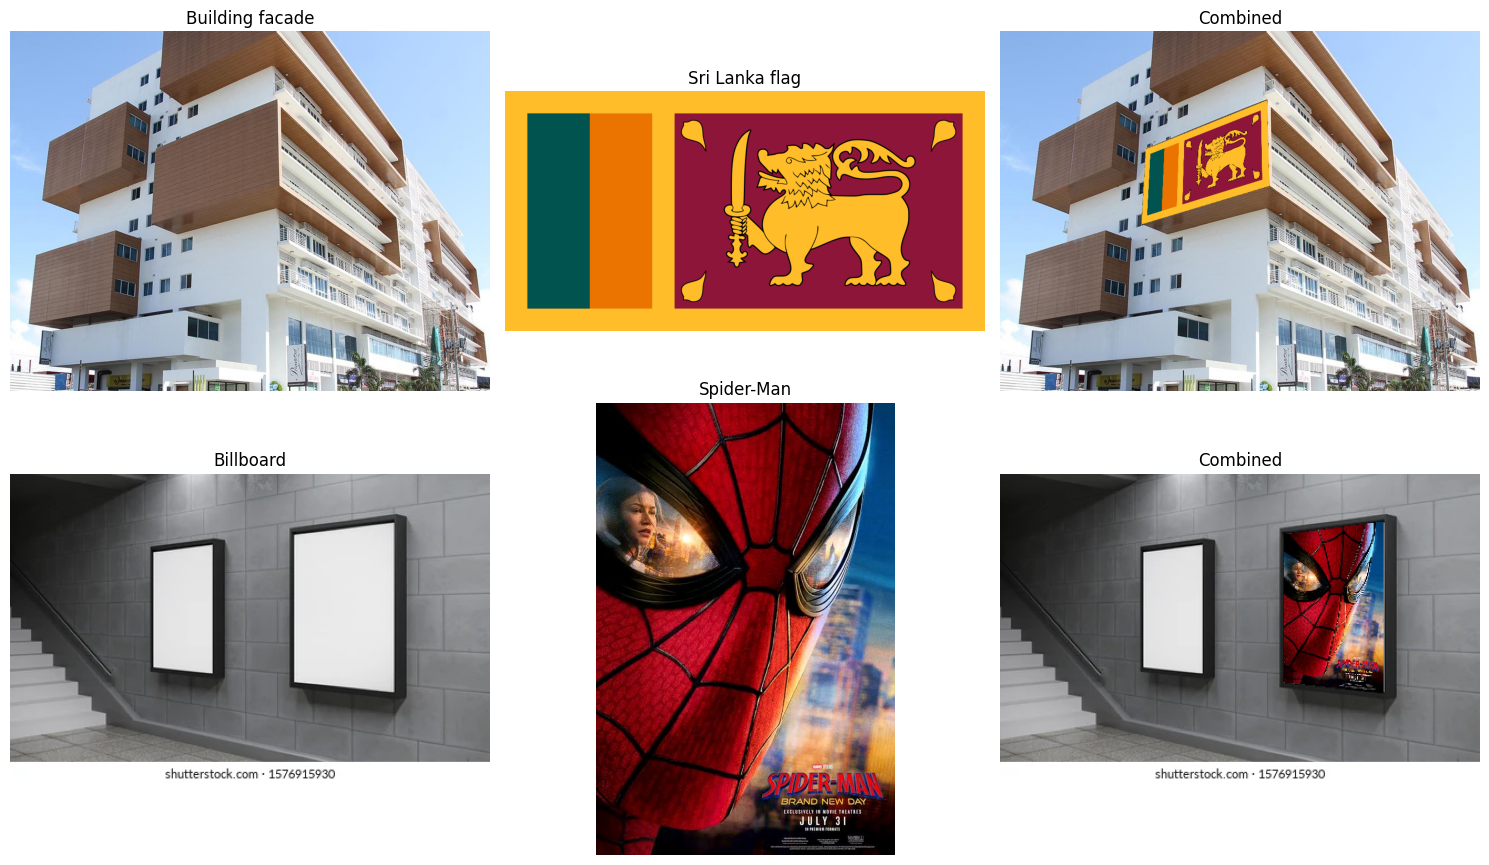

In [ ]:
pairs = [('images/building facade.jpg', 'images/sri_lanka_flag.webp', 'Building facade', 'Sri Lanka flag'),
         ('images/billboard.webp', 'images/spiderman.jpg', 'Billboard', 'Spider-Man')]

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for row, (bg, fg, t1, t2) in zip(axs, pairs):
    pts = click4(bg)
    print(bg, pts)  
    imgs = [cv.imread(bg), cv.imread(fg), overlay(bg, fg, pts)]
    for ax, im, t in zip(row, imgs, [t1, t2, 'Combined']):
        ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB)); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

**Explanation**

- Pair 1 uses a building facade with the Sri Lankan flag, so the overlay demonstrates how the image fits a flat surface viewed at an angle.
- Pair 2 uses a billboard with a Spider-Man image, as billboards provide clear rectangular surfaces for image replacement.
- In both results, the overlaid images follow the perspective of the surfaces. However, small corner-selection errors or differences in lighting can make the overlays look less realistic.

## Question 4 ##